Задача 1. Оценить месячный retention в оформление заказа с помощью когортного анализа.

В рамках исследования необходимо:

- Исследовать датасет и определить, какой вид заказа будет учитываться в retention
- Построить месячный retention
- Проанализировать, чему равен медианный retention 1-го месяца (т.е. взять retention 1-ого месяца для всех когорт и посчитать по этим числам медиану)
- Найти когорту с самым высоким retention на 3-й месяц.
- Проиллюстрировать результаты релевантной визуализацией, удобной для восприятия.

In [1]:
# Импорт библиотек
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Предварительное исследование датафрейма olist_customers_dataset
olist_customers_dataset = pd.read_csv('olist_customers_dataset.csv')

In [3]:
olist_customers_dataset.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [4]:
olist_customers_dataset.shape

(99441, 5)

In [5]:
olist_customers_dataset.dtypes

customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

In [6]:
olist_customers_dataset.isna().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [7]:
# Предварительное исследование датафрейма olist_order_items_dataset
olist_order_items_dataset = pd.read_csv('olist_order_items_dataset.csv')

In [8]:
olist_order_items_dataset.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [9]:
olist_order_items_dataset.shape

(112650, 7)

In [10]:
olist_order_items_dataset.dtypes

order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

In [11]:
olist_order_items_dataset.isna().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [12]:
olist_orders_dataset = pd.read_csv('olist_orders_dataset.csv')

In [13]:
olist_orders_dataset.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [14]:
olist_orders_dataset.shape

(99441, 8)

In [15]:
olist_orders_dataset.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [16]:
olist_orders_dataset.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [17]:
# Объединяем датафреймы olist_customers_dataset и olist_orders_dataset для проведения когортного анализа
full_customer_data = pd.merge(olist_customers_dataset, olist_orders_dataset, on='customer_id', how='inner')

In [18]:
# Исследуем новый датафрейм full_customer_data
full_customer_data.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05 00:00:00
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06 00:00:00
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13 00:00:00
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10 00:00:00
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15 00:00:00


In [19]:
full_customer_data.shape

(99441, 12)

In [20]:
full_customer_data.dtypes

customer_id                        str
customer_unique_id                 str
customer_zip_code_prefix         int64
customer_city                      str
customer_state                     str
order_id                           str
order_status                       str
order_purchase_timestamp           str
order_approved_at                  str
order_delivered_carrier_date       str
order_delivered_customer_date      str
order_estimated_delivery_date      str
dtype: object

In [21]:
full_customer_data.isna().sum()

customer_id                         0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
order_id                            0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [22]:
# Переводим стобцы с датой датафрейма full_customer_data в тип datetime
date_columns = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
full_customer_data[date_columns] = full_customer_data[date_columns].apply(pd.to_datetime)

In [23]:
# Выбираем статус заказа - delivered для проведения когортного анализа и расчета retention, поскольку именно так мы сможем проанализировать реальный клиентский опыт
cohort_df = full_customer_data.query("order_status == 'delivered'").copy()

In [24]:
# Начинаем когортный анализ с определения самой первой даты (order_purchase_timestamp) совершения покупки каждым пользователем 
cohort_df['cohort_month'] = cohort_df.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min')
cohort_df['cohort_month'] = cohort_df['cohort_month'].dt.to_period('M')
#cohort_df['cohort_month'] = cohort_df['cohort_month'].dt.to_timestamp()

In [25]:
cohort_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,cohort_month
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05,2017-05
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06,2018-01
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13,2018-05
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10,2018-03
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15,2018-07


In [26]:
# Определяем номер когорты (cohrt_number)
order_period = cohort_df['order_purchase_timestamp'].dt.to_period('M')
cohort_df['cohort_number'] = (order_period - cohort_df['cohort_month']).apply(lambda x: x.n)

In [27]:
# Строим сводную таблицу по когортам для дальнейшего расчета retention
cohort_pivot = cohort_df.pivot_table(index = 'cohort_month', columns = 'cohort_number', values = 'customer_unique_id', aggfunc = 'nunique')

In [28]:
# Оцениваем полученную таблицу
cohort_pivot

cohort_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,262.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,2.0
2016-12,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,717.0,2.0,2.0,1.0,3.0,1.0,3.0,1.0,1.0,NaN,3.0,1.0,5.0,3.0,1.0,1.0,2.0,3.0,1.0,NaN
2017-02,1628.0,3.0,5.0,2.0,7.0,2.0,4.0,3.0,2.0,3.0,2.0,5.0,2.0,3.0,2.0,1.0,1.0,3.0,NaN,NaN
2017-03,2503.0,11.0,9.0,10.0,9.0,4.0,4.0,8.0,8.0,2.0,9.0,3.0,5.0,3.0,4.0,6.0,2.0,3.0,NaN,NaN
2017-04,2256.0,14.0,5.0,4.0,6.0,6.0,8.0,7.0,7.0,4.0,6.0,2.0,1.0,1.0,2.0,2.0,3.0,NaN,NaN,NaN
2017-05,3451.0,16.0,16.0,10.0,10.0,11.0,14.0,5.0,9.0,9.0,9.0,12.0,8.0,1.0,6.0,7.0,NaN,NaN,NaN,NaN
2017-06,3037.0,15.0,12.0,13.0,9.0,12.0,11.0,7.0,4.0,6.0,9.0,11.0,5.0,5.0,7.0,NaN,NaN,NaN,NaN,NaN


In [29]:
# Рассчитываем месячный retention и форматируем индексы таблицы 
retention_matrix = cohort_pivot.divide(cohort_pivot[0], axis = 0)
retention_matrix.index = retention_matrix.index.strftime('%Y-%m')

In [30]:
# Оцениваем отформатированную таблицу
retention_matrix

cohort_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,1.0,NaN,NaN,NaN,NaN,NaN,0.003817,NaN,NaN,0.003817,NaN,0.003817,NaN,0.003817,NaN,0.003817,NaN,0.003817,0.007634,0.007634
2016-12,1.0,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,1.0,0.002789,0.002789,0.001395,0.004184,0.001395,0.004184,0.001395,0.001395,NaN,0.004184,0.001395,0.006974,0.004184,0.001395,0.001395,0.002789,0.004184,0.001395,NaN
2017-02,1.0,0.001843,0.003071,0.001229,0.004300,0.001229,0.002457,0.001843,0.001229,0.001843,0.001229,0.003071,0.001229,0.001843,0.001229,0.000614,0.000614,0.001843,NaN,NaN
2017-03,1.0,0.004395,0.003596,0.003995,0.003596,0.001598,0.001598,0.003196,0.003196,0.000799,0.003596,0.001199,0.001998,0.001199,0.001598,0.002397,0.000799,0.001199,NaN,NaN
2017-04,1.0,0.006206,0.002216,0.001773,0.002660,0.002660,0.003546,0.003103,0.003103,0.001773,0.002660,0.000887,0.000443,0.000443,0.000887,0.000887,0.001330,NaN,NaN,NaN
2017-05,1.0,0.004636,0.004636,0.002898,0.002898,0.003187,0.004057,0.001449,0.002608,0.002608,0.002608,0.003477,0.002318,0.000290,0.001739,0.002028,NaN,NaN,NaN,NaN
2017-06,1.0,0.004939,0.003951,0.004281,0.002963,0.003951,0.003622,0.002305,0.001317,0.001976,0.002963,0.003622,0.001646,0.001646,0.002305,NaN,NaN,NaN,NaN,NaN


In [31]:
# Проводим расчет медианного retention за 1-й месяц
median_retention_month_1 = retention_matrix[1].median()
print(f'Медианный retention 1-го месяца равен {median_retention_month_1:.2%}')

Медианный retention 1-го месяца равен 0.51%


In [32]:
# Определяем когорту с самым высоким retention на 3 месяц
cohort_3rd_month = retention_matrix[3].idxmax()
max_retention_value = retention_matrix[3].max()
print(f'Когорта с самым высоким значением на 3-й месяц {cohort_3rd_month}')
print(f'Значение когорты: {max_retention_value:.2%}')

Когорта с самым высоким значением на 3-й месяц 2017-06
Значение когорты: 0.43%


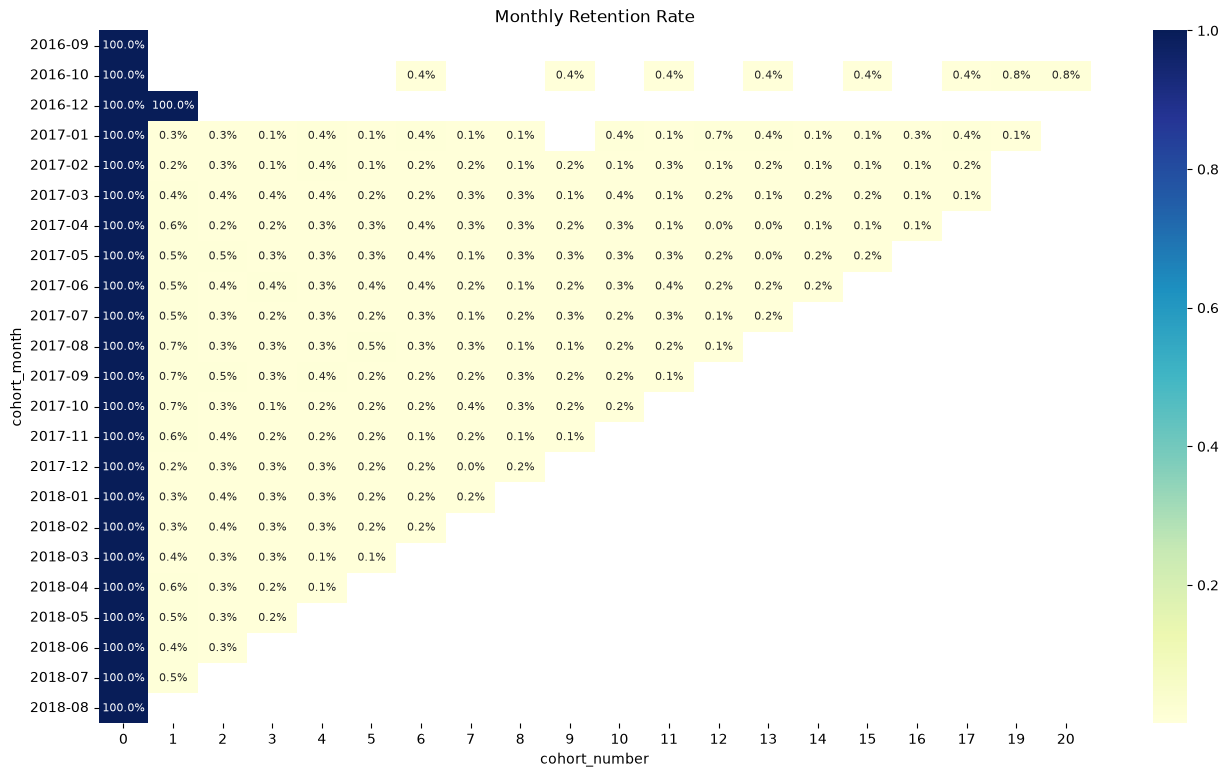

In [33]:
# Визуализируем результаты с помощью инструмента heatmap
plt.figure(figsize = (16,9))
sns.heatmap(retention_matrix, annot=True, fmt='.1%', cmap='YlGnBu', annot_kws={"size": 8})
plt.title('Monthly Retention Rate')
plt.show()

По результатам исследования поведения пользователей следует отметить резкие падения метрики удержания (retention), что показывает низкую лояльность клиентов по отношению к нашему продукту. Эти выводы подтверждает медианный retention 1-го месяца (0.51%). Такое сильное падение, наблюдаемое уже за первый месяц может свидетельствовать о неэффективной работе маркетплейса, поскольку основная часть средств уходит на привлечение новых клиентов, а не удержание старых.

Задача 2. Определить, существует ли product/market fit у маркетплейса.

В рамках исследования необходимо:

- Оценить наличие product/market fit у данного продукта с помощью когортного анализа, полученного на предыдущем шаге.
- Пояснить свою позицию и сформулировать, на чём маркетплейс должен сконцентрироваться в ближайшее время. Если PMF есть, то в какую сторону лучше развивать продукт дальше? Если PMF нет, то какие причины могут быть у этого?
- Подкрепить свои выводы релевантной визуализацией, удобной для восприятия.

Для того, чтобы определить, есть ли у продукта product/market fit, оценим динамику поведения пользователей во времени и построим кривую удержания (Retention Curve). На основе построенного в задаче 1 месячного retention подготовим данные для дальнейшей визуализации.

In [34]:
# Расчет месяца жизни когорты (Lifetime)
median_retention = retention_matrix.median(axis = 0) 

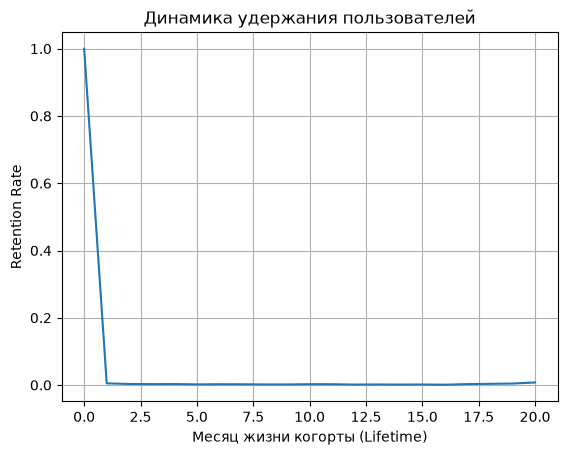

In [35]:
#Построиим Retention Curve и проанализируем полученную динамику.
sns.lineplot(x = median_retention.index, y = median_retention.values)
plt.xlabel("Месяц жизни когорты (Lifetime)")
plt.ylabel("Retention Rate")
plt.title("Динамика удержания пользователей")
plt.grid(True)
plt.show()

На полученном графике видно, что кривая уже на ранних месяцах активновности пользователей резко снижается, достигая плато на уровне retention rate = 0%. Полученные результаты отражают отсутствие product/market fit у маркетплейса, явно иллюстрируя эффект "дырявого ведра". Продукт получает новых пользователей, которые в скором времени (через 1-2 месяца использования) его покидают. В ближайшее время стоит провести анализ причин, почему пользователи не стремятся оформлять повторные заказы, проанализировать аудиторию, оценить функционал приложения, а также, применяются ли какие-либо методы напоминания пользователям об установленном приложении маркетплейса и его ценности.

Задача 3. Определить 5 основных метрик, на которых продакт может сконцентрироваться, чтобы максимизировать прибыль компании.

В первую очередь необходимо:

Определить 5 основных метрик, на которых продакт может сконцентрироваться, чтобы максимизировать прибыль компании.

- Первая метрика должна отражать рост объёма продаж маркетплейса.
- Вторая — показывать объем аудитории, которой продукт доставляет ценность.
- Третья — отражать заинтересованность новых клиентов в продукте (даже если вы не можете посчитать ее на имеющихся у вас данных).
- Четвёртая — отражать вовлеченность клиента в продолжение использования продукта.
- Пятая — отражать денежное выражение вовлеченности клиента.
- Визуализируйте первую, вторую, четвёртую и пятую метрики. Используйте месячную гранулярность и окно в 1 месяц, если это нужно.

Первая метрика должна отражать рост объёма продаж маркетплейса. Выбираем метрику GMV (Gross Merchandise Value или выручка по доставленным заказам)

In [36]:
# Объединяем датафреймы olist_orders_dataset и olist_order_items_dataset для расчета GMV
merged_order_items_data = pd.merge(olist_orders_dataset, olist_order_items_dataset, on='order_id', how='inner')


In [37]:
merged_order_items_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [38]:
merged_order_items_data.shape

(112650, 14)

In [39]:
merged_order_items_data.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date     1194
order_delivered_customer_date    2454
order_estimated_delivery_date       0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
dtype: int64

In [40]:
merged_order_items_data.dtypes

order_id                             str
customer_id                          str
order_status                         str
order_purchase_timestamp             str
order_approved_at                    str
order_delivered_carrier_date         str
order_delivered_customer_date        str
order_estimated_delivery_date        str
order_item_id                      int64
product_id                           str
seller_id                            str
shipping_limit_date                  str
price                            float64
freight_value                    float64
dtype: object

In [41]:
# Переводим стобцы с датой датафрейма merged_order_items_data в тип datetime
date_columns = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
merged_order_items_data[date_columns] = merged_order_items_data[date_columns].apply(pd.to_datetime)

In [42]:
# Рассчитаем выручку по доставленным заказам и группируем значения по месяцам
merged_order_items_data['cohort_month'] = merged_order_items_data['order_purchase_timestamp'].dt.to_period('M')
merged_order_items_data['cohort_month'] = merged_order_items_data['cohort_month'].dt.to_timestamp()


In [43]:
# Группируем данные для визуализации
GMV = merged_order_items_data.query('order_status == "delivered"').groupby('cohort_month')['price'].sum()

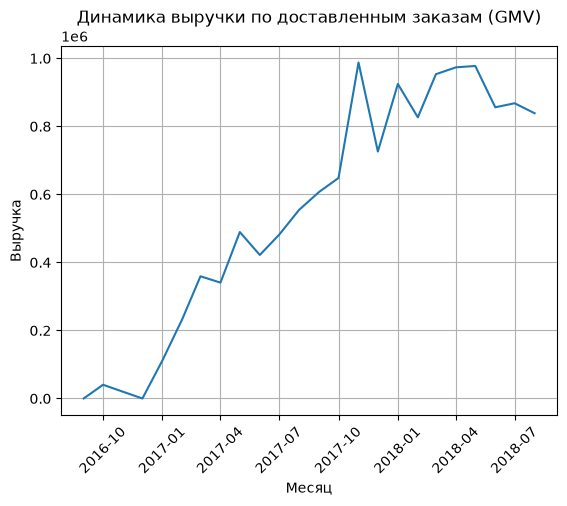

In [44]:
# Визуализруем результаты
sns.lineplot(x = GMV.index, y = GMV.values)
plt.xticks(rotation=45)
plt.xlabel("Месяц")
plt.ylabel("Выручка")
plt.title("Динамика выручки по доставленным заказам (GMV)")
plt.grid(True)
plt.show()

Как видно из полученного графика показатель GVM хоть и имеет резкий рост засчет появления новых пользователей, но стремительно снижается к концу рассматриваемого периода.


Вторая метрика должна показывать объем аудитории, которой продукт доставляет ценность, поэтому выбираем метрику MAU (Monthly Active Users) - количество уникальных активных пользователей в месяц по доставленным заказам.

In [45]:
# Рассчитываем месяц для группировки 
full_customer_data['cohort_month'] = full_customer_data['order_purchase_timestamp'].dt.to_period('M')
full_customer_data['cohort_month'] = full_customer_data['cohort_month'].dt.to_timestamp()

In [46]:
# Группируем уникальных пользователей по месяцам
MAU = full_customer_data.query('order_status == "delivered"').groupby('cohort_month')['customer_unique_id'].nunique()

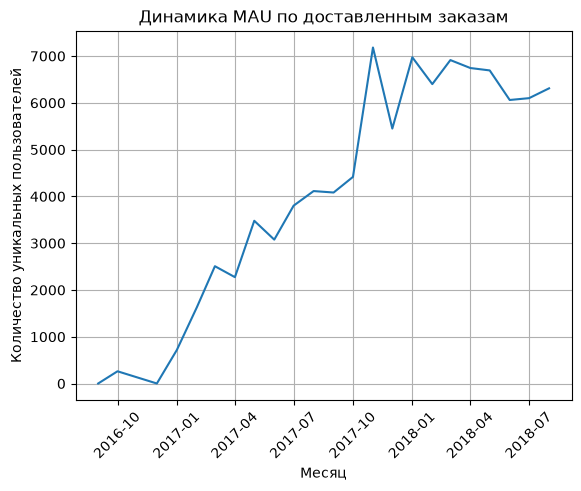

In [47]:
# Визуализируем результаты
sns.lineplot(x = MAU.index, y = MAU.values)
plt.xticks(rotation=45)
plt.xlabel("Месяц")
plt.ylabel("Количество уникальных пользователей")
plt.title("Динамика MAU по доставленным заказам")
plt.grid(True)
plt.show()

Из графика заметим, что кривая также имеет резкие скачки в течение месяца и не выходит на постоянный рост.

Третья метрика должна отражать заинтересованность новых клиентов в продукте  - выбираем число кликов по рекламе или CTR (Click-Through Rate).
Эта метрика будет отражать заинтересованность именно новых клиентов на самом первом этапе их знакомства с продуктом.


Четвёртая метрика должна отражать вовлеченность клиента в продолжение использования продукта - выбираем retention rate.

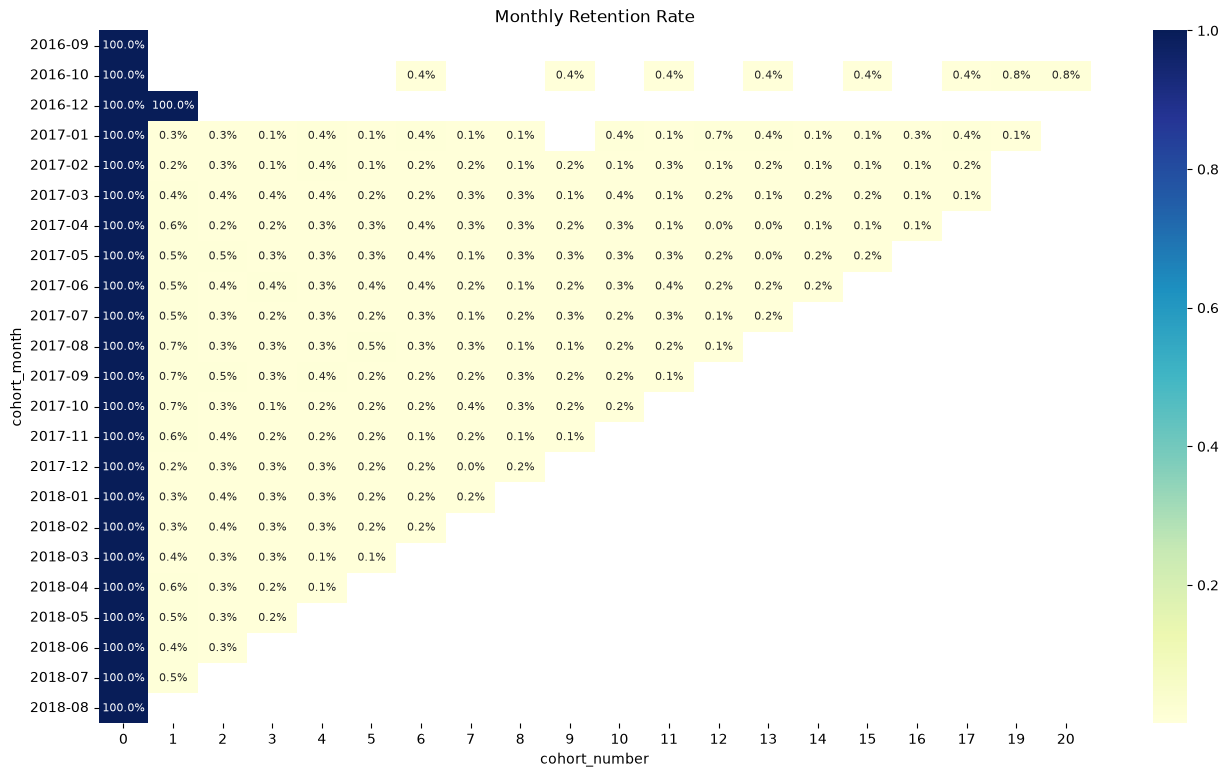

In [48]:
# Визуализируем данную метрику на основе результатов, полученных в задаче 1.
plt.figure(figsize = (16,9))
sns.heatmap(retention_matrix, annot=True, fmt='.1%', cmap='YlGnBu', annot_kws={"size": 8})
plt.title('Monthly Retention Rate')
plt.show()

Как ранее отмечалось, динамика удержания пользователей падает, поскольку зачастую пользователи не имеют привычки возвращаться к нашему продукту.

Пятая метрика должна отражать денежное выражение вовлеченности клиента. Выбираем ARPPU (Average Revenue Per Paying User) или Средний чек платящего пользователя по доставленным заказам.

In [49]:
# Объединяем датафреймы full_customer_data и olist_order_items_dataset
merged_customer_order_item_data = pd.merge(full_customer_data,olist_order_items_dataset, on='order_id', how='inner')

In [50]:
merged_customer_order_item_data.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,cohort_month,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05,2017-05-01,1,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2017-05-22 15:22:12,124.99,21.88
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06,2018-01-01,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-01-18 20:58:32,289.00,46.48
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13,2018-05-01,1,bd07b66896d6f1494f5b86251848ced7,7c67e1448b00f6e969d365cea6b010ab,2018-06-05 16:19:10,139.94,17.79
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10,2018-03-01,1,a5647c44af977b148e0a3a4751a09e2e,7c67e1448b00f6e969d365cea6b010ab,2018-03-27 16:31:16,149.94,23.36
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15,2018-07-01,1,9391a573abe00141c56e38d84d7d5b3b,4a3ca9315b744ce9f8e9374361493884,2018-07-31 10:10:09,230.00,22.25


In [51]:
merged_customer_order_item_data.shape

(112650, 19)

In [52]:
merged_customer_order_item_data.dtypes

customer_id                                 str
customer_unique_id                          str
customer_zip_code_prefix                  int64
customer_city                               str
customer_state                              str
order_id                                    str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
cohort_month                     datetime64[us]
order_item_id                             int64
product_id                                  str
seller_id                                   str
shipping_limit_date                         str
price                                   float64
freight_value                           float64
dtype: object

In [53]:
merged_customer_order_item_data.isna().sum()

customer_id                         0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
order_id                            0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date     1194
order_delivered_customer_date    2454
order_estimated_delivery_date       0
cohort_month                        0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
dtype: int64

In [54]:
# Группируем данные и рассчитываем для последующей визуализации
ARPPU_df = merged_customer_order_item_data.query('order_status == "delivered"').groupby(['cohort_month']).agg({'price': 'sum', 'customer_unique_id': 'nunique'})

In [55]:
ARPPU_df.head()

,price,customer_unique_id
cohort_month,,
2016-09-01,134.97,1
2016-10-01,40325.11,262
2016-12-01,10.90,1
2017-01-01,111798.36,718
2017-02-01,234223.40,1630


In [56]:
ARPPU_df['ARPPU'] = (ARPPU_df['price'] / ARPPU_df['customer_unique_id']).round(2)

In [57]:
ARPPU_df = ARPPU_df.reset_index()

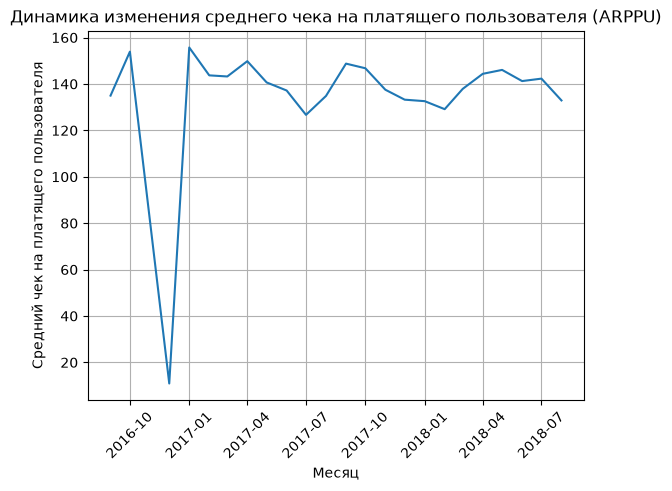

In [58]:
# Визуализруем результаты
sns.lineplot(data = ARPPU_df, x = 'cohort_month', y = 'ARPPU')
plt.xticks(rotation=45)
plt.xlabel("Месяц")
plt.ylabel("Cредний чек на платящего пользователя")
plt.title("Динамика изменения среднего чека на платящего пользователя (ARPPU)")
plt.grid(True)
plt.show()

Показатель среднего чека платящего пользователя по доставленным заказам также имеет резкие скачки, из чего делаем вывод о необходимости повышения заинтересованности в продукте активных пользователей.


Задача 4. Выбрать одну из 3 основных гипотез с помощью фреймворка ICE.

Для этого вам требуется:

Выбрать одну из трёх основных гипотез с помощью фреймворка ICE, которые были сформированы продактом и, кажется, должны улучшить пользовательский опыт в маркетплейсе.

Гипотеза №1 (Н1) - Если исправим баг в системе процессинга заказов, то клиентам не придётся сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Считаем, что мы таким образом избавимся от всех отмен.

Гипотеза №2 (Н2) - Если сократим время до отгрузки заказа, то клиенты перестанут получать свой заказ с запаздыванием, вследствие чего количество заказов увеличится за счёт повторных заказов. 

Гипотеза №3 (Н3) - Если создадим новый способ оплаты, который будет конвертировать клиентов в повторный заказ, то клиенты не будут испытывать трудности при оформлении заказа, вследствие чего количество заказов увеличится за счёт повторных заказов тех, кто раньше не делал повторный заказ.

In [59]:
# Проводим расчет Impact для гипотезы №1
full_customer_data.query('order_purchase_timestamp > "2017-06-01" and (order_status == "canceled" or order_status == "unavailable")')['order_id'].nunique()
impact_1 = 4

Таким образом, мы ожидаем, что количество заказов увеличиться на число отменных, т. е. на 499. Impact = 4 балла

In [60]:
# Проводим расчет Impact для гипотезы №2
customer_delivery = full_customer_data['order_delivered_customer_date'].dt.to_period('D')
estimated_delivery = full_customer_data['order_estimated_delivery_date'].dt.to_period('D')
((full_customer_data.query('order_purchase_timestamp > "2017-06-01" and @customer_delivery > @estimated_delivery')['order_id'].nunique()) * median_retention_month_1).round(0)

impact_2 = 1

Из расчета мы ожидаем, что сократив опаздания доставки, мы увеличим число повторных заказов. Получим увеличение метрики на 31, Impact = 1 балл.

In [61]:
# Проводим расчет Impact для гипотезы №3
one_order_customer = full_customer_data.query('order_purchase_timestamp > "2017-06-01"').groupby('customer_unique_id')['order_id'].nunique().reset_index().query('order_id == 1')['customer_unique_id'].count()
(one_order_customer * median_retention_month_1).round(0)
impact_3 = 4

Из расчетов получили абсолютный прирост заказов на 419, Impact = 4 балла.

In [62]:
# Создаем датафрейм ICE_df, чтобы получить итоговые результаты по приоритезации гипотез.
columns = ['hypothesis', 'impact', 'confidence', 'ease']
ICE_df = pd.DataFrame(columns=columns)

In [63]:
hypothesis_1 = {'hypothesis': 'Н1', 'impact': impact_1, 'confidence': 8, 'ease': 6}
hypothesis_2 = {'hypothesis': 'Н2', 'impact': impact_2, 'confidence': 10, 'ease': 4}
hypothesis_3 = {'hypothesis': 'Н3', 'impact': impact_3, 'confidence': 5, 'ease': 9}

In [64]:
ICE_df = pd.concat([ICE_df, pd.DataFrame([hypothesis_1, hypothesis_2, hypothesis_3])], ignore_index = True)

In [65]:
ICE_df

,hypothesis,impact,confidence,ease
0,Н1,4,8,6
1,Н2,1,10,4
2,Н3,4,5,9


In [66]:
ICE_df['ice'] = ICE_df['impact'] * ICE_df['confidence'] * ICE_df['ease']

Таким образом, по фреймворку ICE гипотеза №1 получила 192 балла, гипотеза №2 - 40 баллов, гипотеза №3 - 180 баллов. Приоритет проверки следует отдать сначала гипотезе №1, затем гипотезе №3 и следом гипотезе №2.


Задача 5. Сформулировать нужные метрики, на которые ваша гипотеза должна повлиять.

Продакт попросил вас:

- Сформулировать метрики, на которые должна повлиять выбранная вами гипотеза.
- Сформулировать хотя бы по одной метрике в категории: целевые, прокси, guardrail и объяснить свой выбор.

 Выбранная гипотеза №1: "Если исправим баг в системе процессинга заказов, то клиентам не придётся сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Считаем, что мы таким образом избавимся от всех отмен."

Целевая метрика, на которую повлияет исправление бага:
 - Выручка по доставленным заказам (GMV), так как наши изменения напрямую ведут к увеличению продаж, соответственно целевая метрика будет отражать изменения в денежном выражении.

Прокси метрика: 
 - Конверсия из оформления заказа в оплату. Она сразу покажет, ушла ли проблема на этапе оформления/обработки, не дожидаясь, пока заказ пройдет весь путь логистики до статуса delivered. 

Guardrail метрика: 

 - Доля возвратов и отмен на более поздних этапах. Поскольку мы пропускаем в доставку больше заказов нам важно убедиться, что среди этих заказов не окажется большой доли "проблемных" (например, с неверным адресом, отсутствием товара на складе или ошибками оплаты), которые просто отменятся позже, что повлияет на затраты на логистику.

ОТЧЕТ: Анализ удержания аудитории удержания аудитории, динамики выручки и приоритезация бэклога
Кому: Продакт-менеджеру маркетплейса (Пете)
От кого: Аналитика данных (Соцковой Екатерины)
Дата: 4 ноября 2026 года

1. Executive Summary (Краткое резюме)
После обнаружения стагнации выручки маркетплейса было проведено исследование поведения активных пользователей. Анализ показал, что стагнация вызвана не отсутствием спроса, а внутренними проблемами: жесткими сбоями в процессинге (отмены) и логистике (опоздания). Продукт находится в состоянии «дырявого ведра» из-за отсутствия Product/Market Fit (PMF) и критически низкого медианного Retention 1-го месяца (0,51%). Дополнительно зафиксирована нестабильность монетизации: метрика ARPPU (средний чек на платящего пользователя) имеет выраженные скачки по месяцам. В ходе исследования также была проведена скоринговая приоритизация бэклога по фреймворку ICE, определившая фокус дальнейших работ.

2. Согласованные показатели эффективности (5 ключевых метрик)
На основе проведенного анализа сформирована система метрик для контроля эффективной деятельности маркетплейса:
1.GMV (Gross Merchandise Value): Объем выручки по доставленным заказам. Основной показатель масштаба бизнеса.
2.MAU (Monthly Active Users): Количество уникальных активных покупателей с доставленными заказами за месяц. Оценка объема активной базы.
3.CTR (Click-Through Rate): Процент кликов по рекламе. Метрика, отражающая интерес новой аудитории.
4.Retention Rate: Доля клиентов, возвращающихся за повторными покупками. Критическая метрика вовлеченности, которая наглядно демонстрирует, что у пользователей маркетплейса пока не сформировалась привычка регулярно пользоваться нашим продуктом.
5.ARPPU (Average Revenue Per Paying User): Средний чек на одного уникального платящего пользователя по доставленным заказам. Денежное выражение вовлеченности, сигнализирующее о необходимости стимулировать продажи и повышать ценность продукта.

Визуализации настоящей динамики рассмотренных метрик:

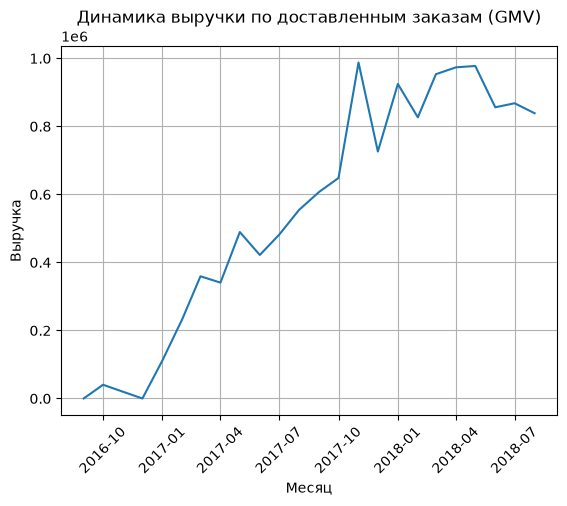

In [67]:
# Визуализация GMV
sns.lineplot(x = GMV.index, y = GMV.values)
plt.xticks(rotation=45)
plt.xlabel("Месяц")
plt.ylabel("Выручка")
plt.title("Динамика выручки по доставленным заказам (GMV)")
plt.grid(True)
plt.show()

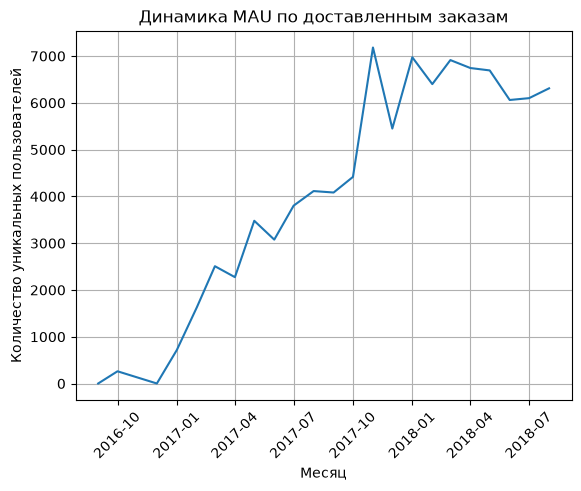

In [68]:
# Визуализация MAU
sns.lineplot(x = MAU.index, y = MAU.values)
plt.xticks(rotation=45)
plt.xlabel("Месяц")
plt.ylabel("Количество уникальных пользователей")
plt.title("Динамика MAU по доставленным заказам")
plt.grid(True)
plt.show()

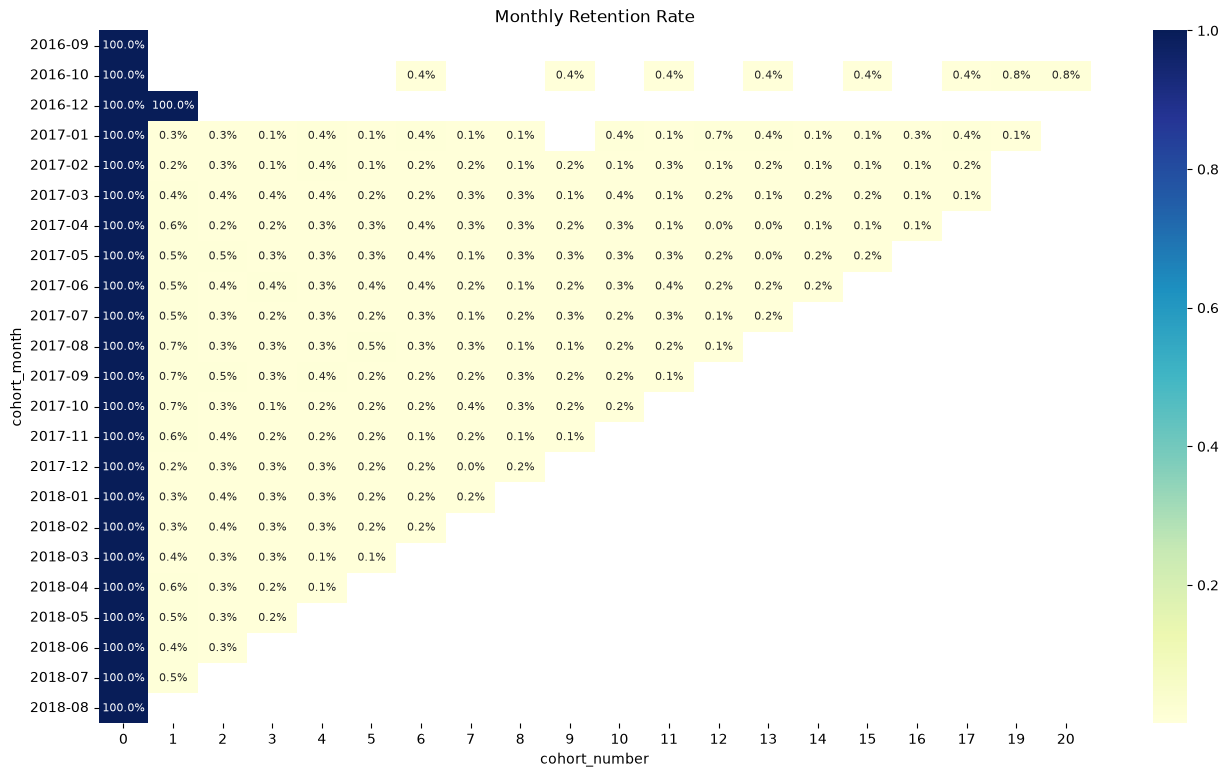

In [69]:
# Визуализация Retention Rate
plt.figure(figsize = (16,9))
sns.heatmap(retention_matrix, annot=True, fmt='.1%', cmap='YlGnBu', annot_kws={"size": 8})
plt.title('Monthly Retention Rate')
plt.show()

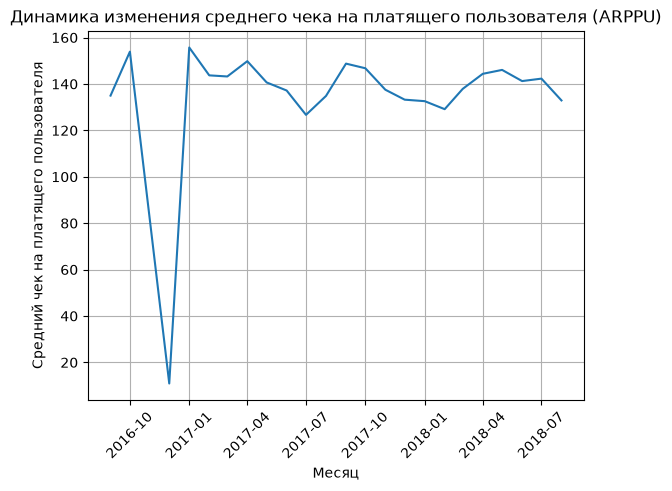

In [70]:
# Визуализация ARPPU
sns.lineplot(data = ARPPU_df, x = 'cohort_month', y = 'ARPPU')
plt.xticks(rotation=45)
plt.xlabel("Месяц")
plt.ylabel("Cредний чек на платящего пользователя")
plt.title("Динамика изменения среднего чека на платящего пользователя (ARPPU)")
plt.grid(True)
plt.show()

3. Приоритезация продуктовых гипотез по фреймворку ICE
Для исправления ситуации с удержанием и падением GMV были оценены три продуктовые гипотезы:
H1: Исправление бага в системе процессинга заказов (устранение технических отмен).
H2: Сокращение опозданий логистики (доставка строго в плановые даты / Estimated Delivery).
H3: Создание нового способа оплаты для клиентов с одним заказом.

Визуализация скорринга ICE:

In [71]:
ICE_df

,hypothesis,impact,confidence,ease,ice
0,Н1,4,8,6,192
1,Н2,1,10,4,40
2,Н3,4,5,9,180


Вывод: Абсолютным приоритетом к разработке становится Гипотеза H1. Она дает максимальный потенциальный прирост в заказах (+499 шт.) и обладает высоким балансом уверенности и простоты внедрения.

4. Дизайн эксперимента для проверки выбранной Гипотезы H1
Формулировка: «Если мы исправим баг в системе процессинга заказов, то клиенты перестанут сталкиваться с необоснованными отменами на этапе оформления, вследствие чего количество доставленных заказов увеличится за счет ликвидации этого технического оттока».

Для запуска релиза и оценки его успешности утверждается следующая система метрик:

Целевая метрика (Primary): Выручка по доставленным заказам (GMV). Изменения напрямую ведут к росту продаж, и данная метрика зафиксирует коммерческий успех релиза в денежном выражении.

Прокси-метрика (Proxy): Конверсия из оформления заказа в успешную оплату (CR). Этот показатель позволит мгновенно (в режиме реального времени) проверить, пропала ли техническая проблема на этапе чекаута, не дожидаясь, пока заказы физически пройдут весь логистический цикл до статуса delivered.

Контролируемая метрика (Guardrail):
Доля отмен и возвратов на более поздних этапах воронки. Важно убедиться, что заказы, которые мы успешно пропустили через процессинг, не начнут массово отменяться позже (например, из-за отсутствия товаров на складах продавцов или ошибок логистики), что создало бы лишь пустые затраты на обработку и доставку.
